# A Tale of Two Cluster State Simulations

In this notebook, we examine two ways of simulating the cluster magnet:

$$ H = \sum_i [-Z_{i-1}X_i Z_{i+1} - h X_i ]  $$

When $h=0$, the system is in the nontrivial $\mathbb{Z}_2 \times \mathbb{Z}_2$ SPT phase, which is an invertible gapped phase whose representative ground states are resources for measurment-based quantum computation.  As $h$ increases, we transition to a trivial paramagnet.  We will simulate this both with a variational quantum eigensolver (VQE) and a tensor network.   

**Variational Quantum Eigensolver**

We start with the variational quantum eigensolver.  Let's import necessary libraries.

In [ ]:
%%capture
!pip install cirq

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.optimize as opt
import cirq

We begin by defining a function that inputs qubits on a circle and a transverse field strength $h$ and returns the above Hamiltonian.

In [ ]:
def build_cluster_Hamiltonian(qubits, h:float) -> cirq.PauliSum:
  #count how many terms and initialize list for loop
  n = len(qubits)
  terms = []

  #append with stabilizer terms
  for j in range(n):
    left = qubits[(j-1)%n]
    center = qubits[j%n]
    right = qubits[(j+1)%n]
    terms.append(-1.0 * (cirq.Z(left) * cirq.X(center) * cirq.Z(right)))

  #append with transverse field terms
  for j in range(n):
    terms.append(-float(h) * cirq.X(qubits[j]))

  #add terms
  return cirq.PauliSum.from_pauli_strings(terms)

To determine which phase the model is in, we comnpute the expectation value of an order parameter.  Rather than local order parameters that characterize (zero-form) SSB states, states in SPT phases are characterized by twisted sector order parameters.  We compute the expectation value of two Z operators with X operators in between.  Let's define such an observable.

In [ ]:
def build_order_parameter(qubits) -> cirq.PauliString:
    """
    Constructs the exact 1D cluster SPT string order parameter:
    O_string = Z_0 * X_1 * X_3 * X_5 * Z_6 (product of odd-site stabilizers K_1 K_3 K_5).
    """
    n = len(qubits)
    # Pick the largest even end-index strictly less than n
    end_idx = (n - 2) if (n % 2 == 0) else (n - 1)

    op = cirq.Z(qubits[0])
    for j in range(1, end_idx, 2):
        op = op * cirq.X(qubits[j])
    op = op * cirq.Z(qubits[end_idx])
    return op

We now explain the VQE.  It is a hybrid algorithm for determining the ground state of a Hamiltonian.  It can be generalized to find the eigenvectors of minimum eigenvalue for many operators, but we will phrase things in Hamiltonian terms.  Given a Hamiltonian, the quantum part of the alforithm uses a parameterized circuit to prepare a variational ansatz.  It then uses the parameterized expectation value of the Hamiltonian in the state as a loss fuction and optimizes classically.

Let's start with a variational ansatz.  It is based on the circuit that prepares the known cluster state ground state.  

In [ ]:
def create_ansatz(qubits, layers: int = 2):
    """
    Builds a layered hardware-efficient ansatz tailored to 1D cluster states:
    - Layer 0: Initial H on all qubits (creates |+>^N, the 0-entanglement reference)
    - Per layer: Ry rotations on all qubits + CZ on alternating even/odd bonds
    """
    n = len(qubits)
    circuit = cirq.Circuit()
    params = []

    # Initialize in |+>^N
    circuit.append(cirq.H.on_each(qubits))

    for l in range(layers):
        # Parameterized Ry rotations
        layer_params = [
            cirq.symbol(f"theta_{l}_{j}") for j in range(n)
        ]
        params.extend(layer_params)
        circuit.append([
            cirq.ry(p).on(q) for q, p in zip(qubits, layer_params)
        ])

        # Even-bond CZ entanglers
        circuit.append([
            cirq.CZ(qubits[j], qubits[(j + 1) % n]) for j in range(0, n, 2)
        ])
        # Odd-bond CZ entanglers
        circuit.append([
            cirq.CZ(qubits[j], qubits[(j + 1) % n]) for j in range(1, n, 2)
        ])

    return circuit, params

Given the ansatz and Hamiltonian, we now make a VQE solver class that implements classical optimization.  We use constained optimzation by linear approximation, which is standard when energies are not smooth functions of parameters.

In [ ]:
class ClusterVQESolver:
    def __init__(self, qubits, layers: int = 2):
        self.qubits = qubits
        self.circuit, self.symbols = create_ansatz(qubits, layers)
        self.simulator = cirq.Simulator()

    def loss(self, param_values, hamiltonian: cirq.PauliSum) -> float:
        param_dict = {
            s: val for s, val in zip(self.symbols, param_values)
        }
        resolved_circuit = cirq.resolve_parameters(self.circuit, param_dict)
        state = self.simulator.simulate(resolved_circuit).final_state_vector
        return float(np.real(hamiltonian.expectation_from_state_vector(
            state, {q: i for i, q in enumerate(self.qubits)}
        )))

    def optimize(self, hamiltonian: cirq.PauliSum, maxiter: int = 250):
        # Initialize angles near 0 to start close to canonical cluster baseline
        init_params = np.random.uniform(-0.1, 0.1, len(self.symbols))
        result = opt.minimize(
            self.loss,
            init_params,
            args=(hamiltonian,),
            method="COBYLA",
            options={"maxiter": maxiter, "disp": False},
        )

        param_dict = {s: val for s, val in zip(self.symbols, result.x)}
        best_circuit = cirq.resolve_parameters(self.circuit, param_dict)
        ground_state = self.simulator.simulate(best_circuit).final_state_vector
        return result.fun, ground_state

We now run the VQE for a variety of values of $h$ to see if we can observe the ordered phase (SPT), disordered phase and phase transition in the order parameter.

In [ ]:
def run_vqe_phase_sweep(n_qubits: int = 8, layers: int = 2):
    qubits = cirq.LineQubit.range(n_qubits)
    qubit_map = {q: i for i, q in enumerate(qubits)}
    h_values = np.linspace(0.0, 2.0, 11)

    solver = ClusterVQESolver(qubits, layers=layers)
    string_op = build_order_parameter(qubits)

    energies = []
    string_orders = []

    print(f"Sweeping h in [0.0, 2.0] for N={n_qubits} qubits (layers={layers})...")

    for h in h_values:
        H = build_cluster_Hamiltonian(qubits, h)
        energy, ground_state = solver.optimize(H)

        # Compute string order parameter <O_string>
        s_val = np.real(string_op.expectation_from_state_vector(
            ground_state, qubit_map
        ))

        energies.append(energy)
        string_orders.append(s_val)

        print(f"h = {h:.2f} | E_0 = {energy:8.4f} | <O_string> = {s_val:6.4f}")


    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)

    # Ground State Energy vs h
    ax1.plot(h_values, energies, "o-", color="#1f77b4", lw=2, ms=6)
    ax1.set_xlabel("Transverse Field $h$", fontsize=12)
    ax1.set_ylabel("Ground State Energy $E_0$", fontsize=12)
    ax1.set_title(f"VQE Ground State Energy (N={n_qubits})", fontsize=13)
    ax1.grid(True, linestyle="--", alpha=0.6)

    # Non-Local String Order vs h
    ax2.plot(h_values, string_orders, "s-", color="#d62728", lw=2, ms=6)
    ax2.axvline(x=1.0, color="gray", linestyle=":", label="Critical transition ($h_c \\approx 1$)")
    ax2.set_xlabel("Transverse Field $h$", fontsize=12)
    ax2.set_ylabel(r"$\langle \mathcal{O}_{\mathrm{string}} \rangle$", fontsize=12)
    ax2.set_title("SPT Order Parameter Decay", fontsize=13)
    ax2.legend(frameon=True)
    ax2.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    plt.show()

    return h_values, energies, string_orders

Now we run.

Sweeping h in [0.0, 2.0] for N=8 qubits (layers=2)...
h = 0.00 | E_0 =  -7.9993 | <O_string> = 0.9996
h = 0.20 | E_0 =  -7.9991 | <O_string> = 0.9995
h = 0.40 | E_0 =  -7.9871 | <O_string> = 0.9987
h = 0.60 | E_0 =  -8.1356 | <O_string> = 0.4324
h = 0.80 | E_0 =  -8.7872 | <O_string> = 0.8737
h = 1.00 | E_0 =  -9.6831 | <O_string> = 0.5243
h = 1.20 | E_0 = -10.7175 | <O_string> = 0.5224
h = 1.40 | E_0 = -11.8248 | <O_string> = 0.1249
h = 1.60 | E_0 = -13.1202 | <O_string> = 0.0141
h = 1.80 | E_0 = -14.4779 | <O_string> = 0.0878
h = 2.00 | E_0 = -16.0003 | <O_string> = 0.0000


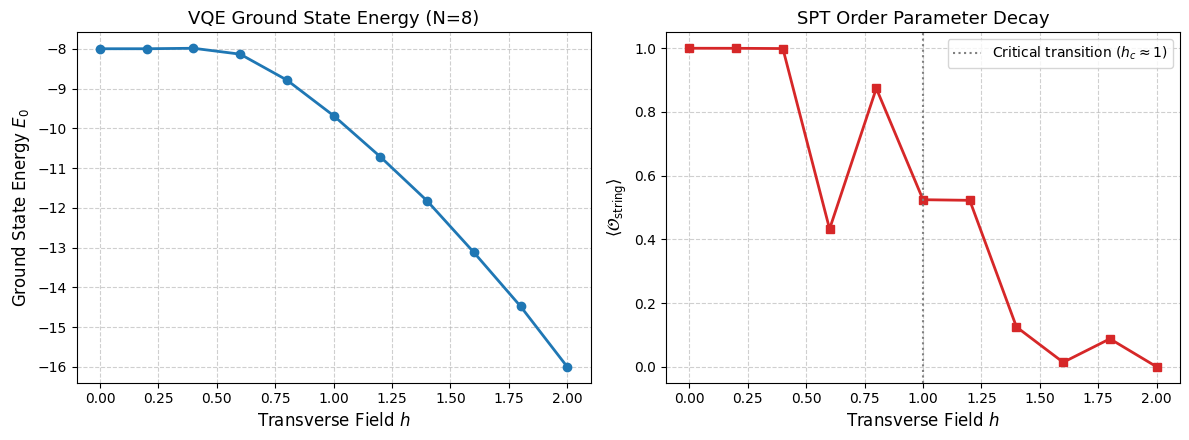

In [ ]:
if __name__ == "__main__":
    h_vals, E_vqe, O_vqe = run_vqe_phase_sweep(n_qubits=8, layers=2)

The above two plots show the ground state energy and the expectation value of the string order parameter as we vary $h$.  Since the term involving $h$ has a negative sign, the energy decrease. is expected. So too is the behavior of the string oprder parameter.  Deep in the SPT phase, it is one.  It deceases past a point near the expected phase transition.  Note that it hits exactly zero.  We will return to this point when we compare to DMRG results.

**Tensor Network and DMRG**

For the sake of comparison, we now find the ground state with density matrix renormalization group (DMRG).  We start by importing a library to help with tensor network manipulations.  We use quimb for its readability and speed.

In [ ]:
%%capture
!pip install -q quimb

In [ ]:
from functools import reduce
import numpy as np
import matplotlib.pyplot as plt
import quimb as qu
import quimb.tensor as qtn

DMRG solves for the ground state of a system by exploring a parameter space of states.  This sounds like a bad idea, since many body Hilbert spaces famously grow exponentially in the number of sites.  Thankfully, it is known that all ground states of 1d gapped phases can be written as matrix product states of the form
$$ \vert \psi \rangle = \sum_{s_0, ..., s_{N-1}} Tr[A_{s_0}^{[0]}...A_{s_{N-1}}^{[N-1]}]\vert s_0,...,s_{N-1}\rangle, $$
where $N$ is the numer of lattice sites, each $s$ is either 0 or 1 (that is, the physical dimension $d$ is 2) and each $A_s^{[j]}$ is a $\chi_{j-1} \times \chi_j$ dimensional matirx ($\chi$ is called the bond dimension).  We use two-site DMRG to minimize $\frac{\langle \psi \vert H \vert \psi \rangle}{\langle \psi \vert \psi \rangle}$.  To facilitate this, we write the Hamiltonian as a matrix product operator (MPO) of the form
$$ H = \sum_{\lbrace s \rbrace, \lbrace s' \rbrace} Tr [W_{s_0,s'_0}^{[0]}.... W_{s_{N-1},s'_{N-1}}^{[N-1]}] \vert \lbrace s \rbrace \rangle \langle \lbrace s' \rbrace\vert ,$$
where each $W$ is a $4 \times 4$ matrix. We minimize the aforementioned Rayleigh quotient in the following sequence of steps:


1.   Use the freedom of rewriting the tensors to ensure that the problem of minimizing the energy remains a Hermitian eigenvalue problem.
2.   Contract $A^{[j-1]} A^{[j]}$ into a $\chi_{j-1}\times d \times d \times \chi_{j+1}$ tensor $\Theta^{[j,j+1]}$.  The products of As to the left and right of the two sites in question are then contracted with the MPO tensors $W^{[j]}$ and $W^{[j+1]}$ to form an effective Hamiltonian of size $d^2 \chi^2 \times d^2 \chi^2$ ($\chi$ is the maximum allowed bond dimension on the chain).  One can then determine the lowest eigenvector $\Theta'^{[j,j+1]}$ using a matrix-free solver.
3.   Reshape $\Theta'^{[j,j+1]}$ into a $d\chi_{j-1} \times d\chi_{j+1}$ matrix, apply single-value decomposition, and retain the largest $\chi$ single values.

We first convert the cluster state to an MPO.



In [ ]:
def build_cluster_mpo(n_qubits: int, h: float) -> qtn.MatrixProductOperator:
    """
    Constructs the exact MPO for H = -sum_j Z_{j-1} X_j Z_{j+1} - h sum_j X_j
    (periodic boundaries) by summing bond-dimension-1 product MPOs and compressing.
    """
    I = qu.eye(2)
    X = qu.pauli("X")
    Z = qu.pauli("Z")

    mpo_terms = []

    # 1. Three-body cluster terms: -Z_{j-1} X_j Z_{j+1}
    for j in range(n_qubits):
        ops = [I] * n_qubits
        ops[(j - 1) % n_qubits] = Z
        ops[j] = X
        ops[(j + 1) % n_qubits] = Z
        ops[0] = -1.0 * ops[0]
        mpo_terms.append(qtn.MPO_product_operator(ops))

    # 2. Single-body transverse field terms: -h X_j
    if h != 0.0:
        for j in range(n_qubits):
            ops = [I] * n_qubits
            ops[j] = -float(h) * X
            mpo_terms.append(qtn.MPO_product_operator(ops))

    mpo = reduce(lambda a, b: a + b, mpo_terms)
    mpo.compress(cutoff=1e-12)
    return mpo

We now run DMRG across the spectrum of $h$ and record the energies and order parameter expectation values for the sake of comparison with the VQE.

In [ ]:
def run_dmrg_comparison(n_qubits=8, h_values=np.linspace(0.0, 2.0, 11)):
    dmrg_energies = []
    dmrg_strings = []

    X = qu.pauli("X")
    Z = qu.pauli("Z")

    # Build the joint Kronecker product operator for <Z_0 X_1 X_3 X_5 Z_6>
    end_idx = (n_qubits - 2) if (n_qubits % 2 == 0) else (n_qubits - 1)
    where = [0] + list(range(1, end_idx, 2)) + [end_idx]
    ops = [Z] + [X for _ in range(1, end_idx, 2)] + [Z]
    string_op_matrix = qu.kron(*ops)

    for h in h_values:
        mpo = build_cluster_mpo(n_qubits, h)

        # Run 2-site DMRG
        dmrg = qtn.DMRG2(mpo, bond_dims=[8, 16, 32], cutoffs=1e-12)
        dmrg.solve(tol=1e-9, verbosity=0)

        psi = dmrg.state
        dmrg_energies.append(np.real(dmrg.energy))

        # Pass the single 2^k x 2^k matrix to local_expectation
        s_val = np.real(psi.local_expectation(string_op_matrix, where=where))
        dmrg_strings.append(s_val)

    return np.array(dmrg_energies), np.array(dmrg_strings)

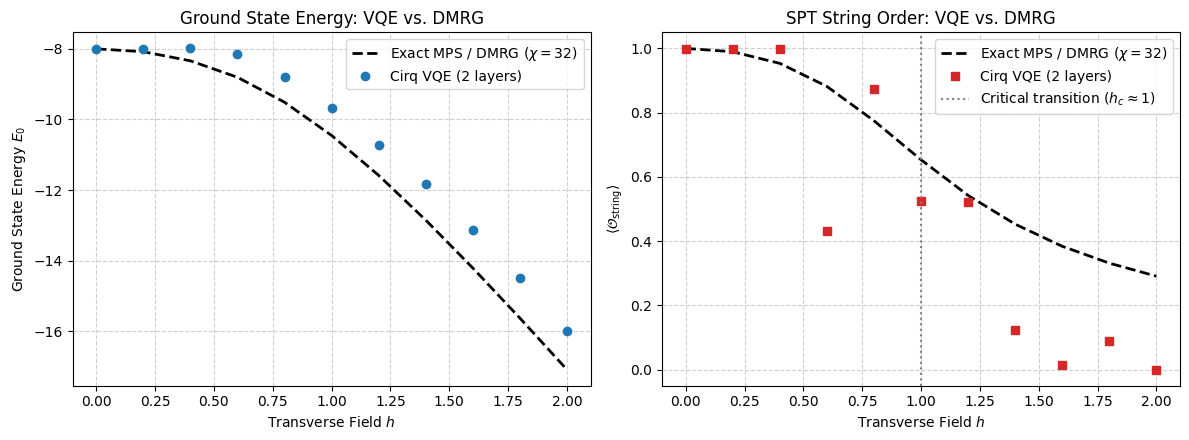

In [ ]:
E_dmrg, O_dmrg = run_dmrg_comparison(n_qubits=8, h_values=h_vals)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5), dpi=100)

ax1.plot(h_vals, E_dmrg, "k--", lw=2, label=r"Exact MPS / DMRG ($\chi=32$)")
ax1.plot(h_vals, E_vqe, "o", color="#1f77b4", ms=6, label="Cirq VQE (2 layers)")
ax1.set_xlabel("Transverse Field $h$")
ax1.set_ylabel("Ground State Energy $E_0$")
ax1.set_title("Ground State Energy: VQE vs. DMRG")
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.6)

ax2.plot(h_vals, O_dmrg, "k--", lw=2, label=r"Exact MPS / DMRG ($\chi=32$)")
ax2.plot(h_vals, O_vqe, "s", color="#d62728", ms=6, label="Cirq VQE (2 layers)")
ax2.axvline(x=1.0, color="gray", linestyle=":", label=r"Critical transition ($h_c \approx 1$)")
ax2.set_xlabel("Transverse Field $h$")
ax2.set_ylabel(r"$\langle \mathcal{O}_{\mathrm{string}} \rangle$")
ax2.set_title("SPT String Order: VQE vs. DMRG")
ax2.legend()
ax2.grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.show()

The above plots compare the DMRG resuls to the VQE results.  The qualitative behavior is similar.  The one obvious difference is that the expectation value of the string order parameter doesn't hit zero.  By examining the ground state energy, we see that the VQE has -16 whereas DMRG hits -17.  This is because the latter includes higher-order effects whereas the former snapped to a product state.  This snapping to a product state is common in shallow VQE.